# softmax 回归

softmax 回归是一个单层神经网络，它的每个输出都依赖于每个输入，因此softmax回归的输出层也是全连接层。

对于分类，有两种理解：
1. 对样本的“硬性”类别感兴趣，即属于哪个类别
2. 也希望得到“软性”类别，即得到属于每个类别的概率

即使我们只关心硬类别,我们仍然使用软类别的模型。


## 分类问题
对于分类问题，要注意到一个细节，如果给类型自然的增加这样的表示：1,2,3。实际上是给它们隐含的增加了一个自然顺序约束！
对于分类问题，更应该采用独热编码（one-hot encoding），独热编码是一个向量，它的分量和类别一样多，类别对应的分量设置为1，其它所有的分量设置为0。


## 全连接层的参数开销
对于任何具有d个输入，q个输出的全连接层，参数开销为O(dq)。将d个输入转换到q个输出的成本，可以减少到O(dq/n)，这个超参数n可以由我们灵活指定，以在实际应用中平衡参数节约和模型的有效性。


## softmax 运算

要将输出视为概率，必须要保证在任何数据上的输出都是非负的且总和为1。

softmax 函数正是这样做的，它将未规范化的预测变换为非负数并且总和为1，同时让模型保持可导的性质。

$$\hat{y}=softmax(o),\text{其中}\hat{y_j}=\frac{exp(o_j)}{\Sigma_k exp(o_k)}$$

softmax运算不会改变为规范化的预测o之间的大小次序，只会确定分配给每个类别的概率。尽管softmax是一个非线性函数，但softmax回归的输出仍然由输入特征的放射变换决定。因此softmax回归是一个线性模型(linear model)。


## 小批量样本的矢量化

小批量样本的特征为$\mathbf{X}\in\mathbb{R}^{n*d}$,权重为$\mathbf{W}\in\mathbb{R}^{d*q}$，偏置为$\mathbf{b}\in\mathbb{R}^{1*q}$。

$$\mathbf{O}=\mathbf{X}\mathbf{W}+\mathbf{b},$$
$$\hat{\mathbf{Y}}=softmax(\mathbf{O})$$


## 损失函数


## 信息论基础
信息论（information theory）涉及编码、解码、发送以及尽可能简洁地处理信息或数据。


### 信息量
自己对于信息量，有个误解，信息量不是信息本身（或信息的多少。。。），而是事件的一个属性！！！

信息量（惊异度）：$-logP(j)$，其中$P(j)$是$j$发生的概率。

纳特(nat)，比特(bit)：信息论通常用$log_2$（单位是比特，代表最少需要几个0/1二进制位来编码）；但深度学习里求导太繁琐了，自然对数$ln$（底为$e$）求导最干净（$(lnx)'=\frac{1}{x}$，所以改用底为$e$，单位叫纳特。两者只差一个常数倍（1 nat $\sim$ 1.44 bit），不影响优化的结果。

### 熵

信息论的核心思想是量化数据中的信息内容。在信息论中，该数值被成为分布P的熵（entropy），可以通过以下方程得到：
$$H[P]=\Sigma_j-P(j)logP(j)$$

如果说信息量是单个事件带来的惊异度，那么熵就是所有可能事件的“平均惊异度”（数学期望）。
物理意义：衡量数据源本身的混乱程度或不确定性。
- 极端确定：一枚两面都是正面的硬币（$P=[1, 0]$），每次结果都毫无悬念，熵$H[P]=0$。
- 极端混乱：一枚均匀硬币（$P=[0.5, 0.5]$，完全猜不准，测试熵达到最大（$ln2 \sim 0.693$ nat，即 1bit）。

- 压缩极限： 信息论基本定理告诉你，$H[P]$ 是无损压缩的理论下限——哪怕你掌握了数据的真实分布 $P$，平均每个样本也至少需要 $H[P]$ 纳特才能编码，不可能再短了。

### 交叉熵

交叉熵中涉及两个角色：真实世界 $P$ 和模型 $Q$。
真实世界按照 $P$ 生成数据，模型主观上认为事件 $j$ 的概率是 $Q(j)$，所以当事件 $j$ 真的发生时，模型感到的惊异度是 $-logQ(j)$，把这种惊异度按真实发生的频率 $P(j)$ 求平均，就得到了交叉熵 $H(P, Q)$。

交叉熵有一个极其重要的性质：$H(P, Q)\gt H(P)$，当且仅当模型的预测完全符合现实 $(Q=P)$ 时取等号。只要模型猜得不准，它就会比“上帝视角”多承受一部分额外的惊异（这部分差值 $H(P, Q) - H(P)$ 就是 $KL$ 散度）。

交叉熵是一个衡量两个概率分布之间差异的很好的度量,它测量给定模型编码数据所需的比特数。

In [61]:
%matplotlib inline

import torch
import torchvision
from matplotlib_inline.backend_inline import set_matplotlib_formats
from torch.utils import data
from torchvision import transforms
from d2l import torch as d2l



def use_svg_display():
    set_matplotlib_formats('svg')

d2l.use_svg_display = use_svg_display

In [62]:
# 读取数据集

trans = transforms.ToTensor()
mnist_train = torchvision.datasets.FashionMNIST(root='../data',train=True,transform=trans,download=True)
mnist_test = torchvision.datasets.FashionMNIST(root='../data',train=False,transform=trans,download=True)

len(mnist_train), len(mnist_test)

(60000, 10000)

In [63]:
mnist_train[0][0].shape

torch.Size([1, 28, 28])

array([<Axes: title={'center': 'ankle boot'}>,
       <Axes: title={'center': 't-shirt'}>,
       <Axes: title={'center': 't-shirt'}>,
       <Axes: title={'center': 'dress'}>,
       <Axes: title={'center': 't-shirt'}>,
       <Axes: title={'center': 'pullover'}>,
       <Axes: title={'center': 'sneaker'}>,
       <Axes: title={'center': 'pullover'}>,
       <Axes: title={'center': 'sandal'}>,
       <Axes: title={'center': 'sandal'}>,
       <Axes: title={'center': 't-shirt'}>,
       <Axes: title={'center': 'ankle boot'}>,
       <Axes: title={'center': 'sandal'}>,
       <Axes: title={'center': 'sandal'}>,
       <Axes: title={'center': 'sneaker'}>,
       <Axes: title={'center': 'ankle boot'}>,
       <Axes: title={'center': 'trouser'}>,
       <Axes: title={'center': 't-shirt'}>], dtype=object)

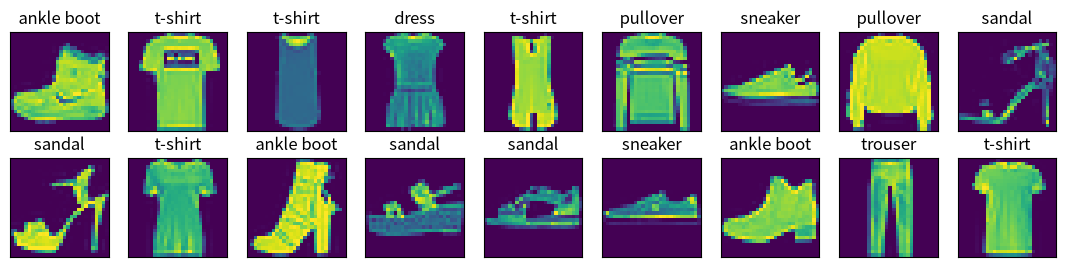

In [64]:
# 用于将数字标签索引与文本名称之间进行转换
def get_fashion_mnist_labels(labels): #@save
    """返回 Fashion-MNIST数据集的文本标签"""
    text_labels = ['t-shirt', 'trouser', 'pullover', 'dress', 'coat', 'sandal', 'shirt', 'sneaker', 'bag', 'ankle boot']
    return [text_labels[int(i)] for i in labels]

# 可视化样本
def show_images(imgs, num_rows, num_cols, titles=None, scale=1.5): #@save
    """绘制图像列表"""
    figsize = (num_cols * scale, num_rows * scale)
    _, axes = d2l.plt.subplots(num_rows, num_cols, figsize=figsize, squeeze=False)
    axes = axes.flatten()
    for i, (ax, img) in enumerate(zip(axes, imgs)):
        if torch.is_tensor(img):
            # 图片张量
            ax.imshow(img.numpy())
        else:
            # PIL 图片
            ax.imshow(img)
        ax.axes.get_xaxis().set_visible(False)
        ax.axes.get_yaxis().set_visible(False)
        if titles:
            ax.set_title(titles[i])
    return axes

X, y = next(iter(data.DataLoader(mnist_train, batch_size=18)))
show_images(X.reshape(18, 28, 28), 2, 9, titles=get_fashion_mnist_labels(y))

In [65]:
# 读取小批量

batch_size = 256


def get_dataloader_workers(): #@save
    """使用4个进程来读取数据"""
    return 4

train_iter = data.DataLoader(mnist_train, batch_size, shuffle=True, num_workers=get_dataloader_workers())

timer = d2l.Timer()
for X,y in train_iter:
    continue

f'{timer.stop():.2f} sec'

'0.47 sec'

In [66]:
# 整合所有组件

def load_data_fashion_mnist(batch_size, resize=None): #@save
    """下载Fashion-MNIST数据集，然后将其加载到内存中"""
    steps = [transforms.Resize(resize), transforms.ToTensor()] if resize is not None else [transforms.ToTensor()]
    trans = transforms.Compose(steps)
    mnist_train = torchvision.datasets.FashionMNIST(root='../data', train=True, transform=trans, download=True)
    mnist_test = torchvision.datasets.FashionMNIST(root='../data', train=False, transform=trans, download=True)
    return (data.DataLoader(mnist_train, batch_size, shuffle=True, num_workers=get_dataloader_workers()),
            data.DataLoader(mnist_test, batch_size, shuffle=True, num_workers=get_dataloader_workers()))
    

train_iter, test_iter = load_data_fashion_mnist(32, resize=64)
for X,y in train_iter:
    print(X.shape, X.dtype, y.shape, y.dtype)
    break

torch.Size([32, 1, 64, 64]) torch.float32 torch.Size([32]) torch.int64


In [67]:
# softmax 从零实现

import torch
from IPython import display
from d2l import torch as d2l

batch_size = 256
train_iter, test_iter = d2l.load_data_fashion_mnist(batch_size=batch_size)

## 初始化模型参数
num_inputs = 784  # 28*28
num_ouputs = 10   # types

W = torch.normal(0, 0.01, size=(num_inputs, num_ouputs), requires_grad=True)
b = torch.zeros(num_ouputs, requires_grad=True)

## 定义 softmax 操作
def softmax(X):
    X_exp = torch.exp(X)
    partition = X_exp.sum(1, keepdim=True)
    return X_exp /partition  # 这里应用了广播机制

In [68]:
## test
X = torch.normal(0, 1, (2, 5))
X_prob = softmax(X)
X, X_prob, X_prob.sum(1)

(tensor([[-0.9758,  0.5743,  0.6631, -1.0140,  0.1107],
         [ 0.2561,  0.3710, -0.6013, -0.5234, -0.4730]]),
 tensor([[0.0676, 0.3186, 0.3482, 0.0651, 0.2004],
         [0.2868, 0.3217, 0.1217, 0.1315, 0.1383]]),
 tensor([1.0000, 1.0000]))

In [69]:
# 定义模型
def net(X):
    return softmax(torch.matmul(X.reshape((-1, W.shape[0])), W) + b)

In [70]:
# 定义损失函数
# y 每个样本的真实类别编号
y = torch.tensor([0, 2])
# y_hat 模型给这些类别的预测概率
y_hat = torch.tensor([[0.1, 0.3, 0.6], [0.3, 0.2, 0.5]])

def cross_entropy(y_hat, y):
    # y_hat[range(len(y_hat)), y] => 提取的是模型给每个样本的真实类别分配的预测概率！！ 这一点，自己一开始没有想明白
    return -torch.log(y_hat[range(len(y_hat)), y])

# 因为是 one-hot 编码，其它的都明确是 0，所以这样也是交叉熵
cross_entropy(y_hat, y)

tensor([2.3026, 0.6931])

In [71]:
# 分类精度：正确预测数量与总预测数量之比
# 虽然直接优化精度可 能很困难(因为精度的计算不可导),但精度通常是我们最关心的性能衡量标准,我们在训练分类器时几乎总 会关注它
#
# 其实神经网络的核心，还是是否可导！！！

def accuracy(y_hat, y): #@save
    """计算预测正确的数量"""
    # 这里是将 y_hat 标记为其最大的元素的列，如果已经是1维的了，会跳过
    if len(y_hat.shape) > 1 and y_hat.shape[1] > 1:
        y_hat = y_hat.argmax(axis=1)

    # .type(y.dtype) 将预测编号转成与标签相同的数据类型
    # '==' 再逐个比较
    cmp = y_hat.type(y.dtype) == y
    # 这里返回的是预测正确的个数（也就是 1.0 的个数）
    return float(cmp.type(y.dtype).sum())

print(accuracy(y_hat, y) / len(y))

class Accumulator:#@save
    def __init__(self, n):
        self.data = [0.0] * n
    
    def add(self, *args):
        # 会分别对 data 中的元素逐一与 *args 相加
        self.data = [a + float(b) for a, b in zip(self.data, args)]
    
    def reset(self):
        self.data = [0.0] * len(self.data)
    
    def __getitem__(self, idx):
        return self.data[idx]


def evaluate_accuracy(net, data_iter): #@save
    """计算在指定数据集上模型的精度"""
    # 如果 net 是 PyTorch 模型，就切换到评估模式，例如，Dropout 层在评估时会停止随机丢弃神经元
    if isinstance(net, torch.nn.Module):
        net.eval()
    # 这里存两个数，是因为会分多个批次送入模型
    metric = Accumulator(2) # 累计预测正确数、累计样本数
    # no_grad() 让pytorch在这段评估期间跳过梯度记录，节省内存
    #    >>> eval() 控制某些层在前向计算时的行为，no_grad() 控制是否记录梯度所需的信息
    with torch.no_grad():
        for X, y in data_iter:
            """
                y_hat = net(X)                       # 模型对这一批样本做预测
                num_correct = accuracy(y_hat, y)     # 这一批预测对了几个
                num_samples = y.numel()              # 单标签分类中，一个样本对应一个标签
                metric.add(num_correct, num_samples)
            """
            metric.add(accuracy(net(X), y), y.numel())
    return metric[0] / metric[1]

evaluate_accuracy(net, test_iter)

# 为什么训练用交叉熵，评估看准确率  ==> 模型需要看是否进步了
# 模型已经把真实类别的概率从 10% 提高到 40%，但最高分仍属于类别 2，所以准确率看不到这次进步。只要最高分的类别没变，准确率就保持不动，梯度几乎处处为零。 交叉熵则随着真实类别概率的提高而下降，可以为参数更新提供梯度。
# 因此，“可导”这个要求要放在用梯度训练模型的环节理解。评估时只需回答“模型最终选对了多少次”，此时直接计数就够了。

0.5


0.0911

In [72]:
# 训练

def train_epoch_ch3(net, train_iter, loss, updater): #@save
    """训练模型一个迭代周期"""
    # 将模型设置为训练模式
    if isinstance(net, torch.nn.Module):
        net.train()
    # 训练损失总和、训练准确度总和、样本数
    metric = Accumulator(3)
    for X, y in train_iter:
        # 计算梯度并更新参数
        y_hat = net(X)
        l = loss(y_hat, y)
        if isinstance(updater, torch.optim.Optimizer):
            # 使用 PyTorch 内置的优化器和损失函数
            updater.zero_grad()
            l.mean().backward()
            updater.step()
        else:
            l.sum().backward()
            updater(X.shape[0])
        metric.add(float(l.sum()), accuracy(y_hat, y), y.numel())
    # 返回训练损失和训练精度
    return metric[0] / metric[2], metric[1] / metric[2]


In [73]:
class Animator:  # @save
    """在动画中绘制数据。"""

    def __init__(
        self,
        xlabel=None,
        ylabel=None,
        legend=None,
        xlim=None,
        ylim=None,
        xscale="linear",
        yscale="linear",
        fmts=("-", "m--", "g-.", "r:"),
        nrows=1,
        ncols=1,
        figsize=(3.5, 2.5),
    ):
        # 增量地绘制多条线
        if legend is None:
            legend = []

        d2l.use_svg_display()
        self.fig, self.axes = d2l.plt.subplots(nrows, ncols, figsize=figsize)
        if nrows * ncols == 1:
            self.axes = [self.axes]

        # 保存坐标轴配置，以便每次重绘后重新应用
        self.config_axes = lambda: d2l.set_axes(
            self.axes[0], xlabel, ylabel, xlim, ylim, xscale, yscale, legend
        )
        self.X, self.Y, self.fmts = None, None, fmts

    def add(self, x, y):
        """向每条曲线添加一个数据点，并刷新图表。"""
        if not hasattr(y, "__len__"):
            y = [y]
        n = len(y)

        if not hasattr(x, "__len__"):
            x = [x] * n

        if not self.X:
            self.X = [[] for _ in range(n)]
        if not self.Y:
            self.Y = [[] for _ in range(n)]

        for i, (a, b) in enumerate(zip(x, y)):
            if a is not None and b is not None:
                self.X[i].append(a)
                self.Y[i].append(b)

        self.axes[0].cla()
        for x, y, fmt in zip(self.X, self.Y, self.fmts):
            self.axes[0].plot(x, y, fmt)

        self.config_axes()
        display.display(self.fig)
        display.clear_output(wait=True)

In [74]:
def train_ch3(net, train_iter, test_iter, loss, num_epochs, updater):  # @save
    """训练模型（定义见第 3 章）。"""
    if num_epochs < 1:
        raise ValueError('num_epochs 必须至少为 1')
    animator = Animator(
        xlabel="epoch",
        xlim=[1, num_epochs],
        ylim=[0.3, 0.9],
        legend=["train loss", "train acc", "test acc"],
    )

    for epoch in range(num_epochs):
        train_metrics = train_epoch_ch3(net, train_iter, loss, updater)
        test_acc = evaluate_accuracy(net, test_iter)
        animator.add(epoch + 1, train_metrics + (test_acc,))

        # 只检查最后一轮的指标
        if epoch + 1 == num_epochs:
            train_loss, train_acc = train_metrics
            assert train_loss < 0.5, train_loss
            assert 0.7 < train_acc <= 1, train_acc
            assert 0.7 < test_acc <= 1, test_acc

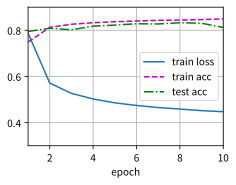

In [ ]:
# 从零开始训练
lr = 0.1
def updater(batch_size):
    return d2l.sgd([W, b], lr, batch_size)

num_epochs = 10
train_ch3(net, train_iter, test_iter, cross_entropy, num_epochs, updater)

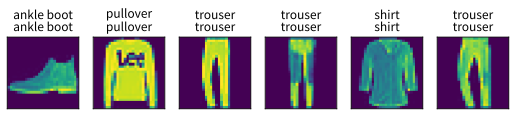

In [76]:
def predict_ch3(net, test_iter, n=6):  # @save
    """显示测试集中前 n 张图像的真实标签和预测标签。"""
    batch = next(iter(test_iter), None)
    if batch is None:
        return
    X, y = batch

    trues = d2l.get_fashion_mnist_labels(y)
    preds = d2l.get_fashion_mnist_labels(net(X).argmax(axis=1))

    # 每张图的标题分两行：上面是真实标签，下面是预测标签
    titles = [true + "\n" + pred for true, pred in zip(trues, preds)]

    d2l.show_images(
        X[:n].reshape((n, 28, 28)),
        1,
        n,
        titles=titles[:n],
    )


predict_ch3(net, test_iter)